In [1]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [3]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")


In [4]:
df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")

# Profil disciplinaire

In [9]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [37]:
gb_data, df_exp = split_multiple_choices(df0, column='q10_type_data', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df0, column='q5_logiciel_traitement_rec', index = "q45_clé", sep = '|')


In [38]:
df_rf = df_exp[["q45_clé", 'q10_type_data']].copy()
df_rf.loc[df_rf.q10_type_data.isna(), "q10_type_data"] = "Aucune donnée"
df_rf.loc[df_rf.q10_type_data=="Aucune donnée"]
df_rf["value"] = 1
df_rf["question"] = 'q10_type_data'
df_rf.loc[df_rf.q45_clé=="82N2-HDNU"]

,q45_clé,q10_type_data,value,question
107,82N2-HDNU,Données textuelles ou documentaires,1,q10_type_data
107,82N2-HDNU,Données géographiques ou spatiales,1,q10_type_data
107,82N2-HDNU,Métadonnées,1,q10_type_data


In [47]:
df_d = df_exp1[["q45_clé", 'q5_logiciel_traitement_rec']].copy()
df_d.loc[df_d.q5_logiciel_traitement_rec.isna(), "q5_logiciel_traitement_rec"] = "Aucun logiciel"
df_d.loc[df_d.q5_logiciel_traitement_rec=="Aucun logiciel"]
df_d["value"] = 1
df_d["question"] = 'q5_logiciel_traitement_rec'
df_d["nb"] = df_d.groupby(["q5_logiciel_traitement_rec"])["q45_clé"].transform("count")
df_d2 = df_d.loc[df_d.nb>=5]
df_d2


,q45_clé,q5_logiciel_traitement_rec,value,question,nb
0,PS8W-TJ9P,Aucun logiciel,1,q5_logiciel_traitement_rec,25
1,GNEG-5QXQ,Aucun logiciel,1,q5_logiciel_traitement_rec,25
2,FCCB-GMYA,excel,1,q5_logiciel_traitement_rec,79
3,CV3G-95CT,r,1,q5_logiciel_traitement_rec,38
4,9EAP-NB4B,excel,1,q5_logiciel_traitement_rec,79
...,...,...,...,...,...
116,HRZG-6JGE,r,1,q5_logiciel_traitement_rec,38
116,HRZG-6JGE,excel,1,q5_logiciel_traitement_rec,79
117,32TW-JLY5,python,1,q5_logiciel_traitement_rec,23
117,32TW-JLY5,excel,1,q5_logiciel_traitement_rec,79


In [48]:
df_df=pd.concat([df_d2.rename(columns={"q5_logiciel_traitement_rec":"variable"}), df_rf.rename(columns={"q10_type_data":"variable"},)])
#df_df = df_df.loc[~df_df.variable.isna()]


,q45_clé,variable,value,question,nb
0,PS8W-TJ9P,Aucun logiciel,1,q5_logiciel_traitement_rec,25.0
1,GNEG-5QXQ,Aucun logiciel,1,q5_logiciel_traitement_rec,25.0
2,FCCB-GMYA,excel,1,q5_logiciel_traitement_rec,79.0
3,CV3G-95CT,r,1,q5_logiciel_traitement_rec,38.0
4,9EAP-NB4B,excel,1,q5_logiciel_traitement_rec,79.0
...,...,...,...,...,...
117,32TW-JLY5,Données du web,1,q10_type_data,NaN
117,32TW-JLY5,Données statistiques,1,q10_type_data,NaN
117,32TW-JLY5,Données multimédia,1,q10_type_data,NaN
118,6GVE-N5NJ,Données expérimentales ou d'observation,1,q10_type_data,NaN


In [49]:
def create_term_term_matrix(data, what, list_columns, value):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=0)
    
    term_term = np.dot(table, table.T) # multiplication de la transposé de
    return term_term, table

In [50]:
term_term, table = create_term_term_matrix(data = df_df,  what ="q45_clé", list_columns=["variable"], value="value")
table

/tmp/ipykernel_2651/4206556320.py:2: FutureWarning: The provided callable <function sum at 0x7f50682bb7e0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


variable,Aucun logiciel,Aucune,"Autre, précisez lesquelles",Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,Données textuelles ou documentaires,Métadonnées,excel,jamovi,nvivo,python,r
q45_clé,,,,,,,,,,,,,,,,,
2DRU-P3AV,0,0,0,1,1,1,1,0,1,0,1,1,1,0,0,1,0
2JQN-P9PA,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1
2QNC-8AAQ,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0
2Y89-7BR9,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0
32TW-JLY5,0,0,0,1,0,1,1,0,1,1,1,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,0,0,0,1,1,1,0,0,0,1,1,0,1,0,0,0,0
YTMC-B4DP,0,0,0,1,1,0,1,0,1,1,0,0,1,1,0,0,1
ZB5S-ABHN,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1


In [45]:
var_os = [x for x in df0.columns if "q5_" in x]

var_os

['q5_r',
 'q5_python',
 'q5_excel',
 'q5_julia',
 'q5_stata',
 'q5_sas',
 'q5_aucun',
 'q5_autre',
 'q5_1_other_lang',
 'q5_1_other_lang_rec',
 'q5_logiciel_traitement_rec',
 'q5_family_logi']

In [229]:
for col in df_os.columns:
    df_os[col] = df_os.apply(lambda row: f'{col.split("_")[0]}_{str(row[col])}', 1) # lower sentence

In [230]:
df_os

,q1_so_principles,q2_hal_depot,octavi_depot_rec,depot_entrepot
q45_clé,,,,
GNEG-5QXQ,"q1_Oui, un peu","q2_Oui, une fois",octavi_Non,depot_Non
FCCB-GMYA,"q1_Oui, tout à fait","q2_Oui, plusieurs fois",octavi_Ne connait pas,depot_Non
CV3G-95CT,"q1_Oui, un peu","q2_Oui, une fois",octavi_Non,depot_Oui
M5L8-UM9F,"q1_Oui, un peu","q2_Oui, systématiquement",octavi_Ne connait pas,depot_Non
HT8V-PSKZ,"q1_Oui, un peu","q2_Oui, plusieurs fois",octavi_Non,depot_Non
...,...,...,...,...
MLSN-NBUS,"q1_Oui, un peu","q2_Oui, plusieurs fois",octavi_Non,depot_Oui
WAR9-LFJP,"q1_Oui, un peu","q2_Oui, systématiquement",octavi_Non,depot_Non
HRZG-6JGE,"q1_Oui, un peu","q2_Oui, plusieurs fois",octavi_Non,depot_Non


In [51]:
!pip install fanalysis

In [52]:
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [53]:
sns.set(context='notebook', style='white', rc={'figure.figsize':(14,10)})

In [54]:
#analyse avec fanalysis
from fanalysis.mca import MCA

In [58]:
table

variable,Aucun logiciel,Aucune,"Autre, précisez lesquelles",Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,Données textuelles ou documentaires,Métadonnées,excel,jamovi,nvivo,python,r
q45_clé,,,,,,,,,,,,,,,,,
2DRU-P3AV,0,0,0,1,1,1,1,0,1,0,1,1,1,0,0,1,0
2JQN-P9PA,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1
2QNC-8AAQ,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0
2Y89-7BR9,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0
32TW-JLY5,0,0,0,1,0,1,1,0,1,1,1,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,0,0,0,1,1,1,0,0,0,1,1,0,1,0,0,0,0
YTMC-B4DP,0,0,0,1,1,0,1,0,1,1,0,0,1,1,0,0,1
ZB5S-ABHN,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1


In [63]:
#récupération des variables actives
DActives = table.copy()
#print(DActives)

#récupération des infos - nombre de variables
p = DActives.shape[1]
print(p)
#nombre d'observations
n = DActives.shape[0]
print(p, n)
#codage en 0/1
X = pd.get_dummies(DActives,prefix='',prefix_sep='', dtype=int)

M = X.shape[1]

17
17 119


variable,Aucun logiciel,Aucune,"Autre, précisez lesquelles",Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,Données textuelles ou documentaires,Métadonnées,excel,jamovi,nvivo,python,r
q45_clé,,,,,,,,,,,,,,,,,
2DRU-P3AV,0,0,0,1,1,1,1,0,1,0,1,1,1,0,0,1,0
2JQN-P9PA,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1
2QNC-8AAQ,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0
2Y89-7BR9,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0
32TW-JLY5,0,0,0,1,0,1,1,0,1,1,1,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,0,0,0,1,1,1,0,0,0,1,1,0,1,0,0,0,0
YTMC-B4DP,0,0,0,1,1,0,1,0,1,1,0,0,1,1,0,0,1
ZB5S-ABHN,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1


In [60]:
acm = MCA(row_labels=DActives.index,var_labels=DActives.columns)
acm.fit(DActives.values)
#propriétés
print(dir(acm))
np.transpose(acm.eig_)

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_binarization', '_compute_stats', '_compute_svd', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_params', 'c_', 'col_contrib_', 'col_coord_', 'col_cos2_', 'col_labels', 'col_labels_', 'col_labels_short_', 'col_labels_short_temp_', 'col_labels_

array([[1.86498167e-01, 1.86498167e+01, 1.86498167e+01],
       [1.23244147e-01, 1.23244147e+01, 3.09742315e+01],
       [1.09383428e-01, 1.09383428e+01, 4.19125742e+01],
       [8.44094320e-02, 8.44094320e+00, 5.03535174e+01],
       [6.98236165e-02, 6.98236165e+00, 5.73358791e+01],
       [6.51760006e-02, 6.51760006e+00, 6.38534791e+01],
       [5.49756693e-02, 5.49756693e+00, 6.93510461e+01],
       [4.86263240e-02, 4.86263240e+00, 7.42136785e+01],
       [4.36932277e-02, 4.36932277e+00, 7.85830012e+01],
       [4.15099778e-02, 4.15099778e+00, 8.27339990e+01],
       [4.01087049e-02, 4.01087049e+00, 8.67448695e+01],
       [2.80431543e-02, 2.80431543e+00, 8.95491849e+01],
       [2.71598353e-02, 2.71598353e+00, 9.22651685e+01],
       [2.56364295e-02, 2.56364295e+00, 9.48288114e+01],
       [2.35431626e-02, 2.35431626e+00, 9.71831277e+01],
       [1.82299676e-02, 1.82299676e+00, 9.90061244e+01],
       [9.93875560e-03, 9.93875560e-01, 1.00000000e+02]])

In [64]:
#nombre max de facteurs
Hmax = p
print(M, Hmax)
#valeurs propres
valeurs_propres = pd.DataFrame(np.transpose(acm.eig_),columns=['Val_P','%','Cumul %'],index=range(1,Hmax+1))
valeurs_propres

17 17


,Val_P,%,Cumul %
1,0.186498,18.649817,18.649817
2,0.123244,12.324415,30.974231
3,0.109383,10.938343,41.912574
4,0.084409,8.440943,50.353517
5,0.069824,6.982362,57.335879
6,0.065176,6.517600,63.853479
7,0.054976,5.497567,69.351046
8,0.048626,4.862632,74.213678
9,0.043693,4.369323,78.583001
10,0.041510,4.150998,82.733999


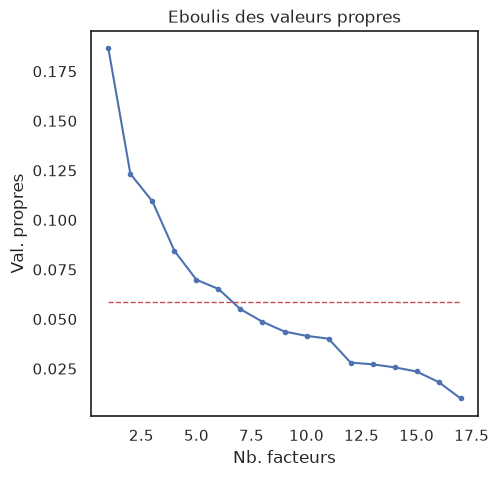

In [65]:
#librairie graphique
import matplotlib.pyplot as plt
#éboulis des v.p.
fix,ax = plt.subplots(figsize=(5,5))
ax.plot(range(1,Hmax+1),acm.eig_[0],".-")
ax.set_xlabel("Nb. facteurs")
ax.set_ylabel("Val. propres")
plt.title("Eboulis des valeurs propres")
#seuil - Règle de Kaiser
ax.plot([1,Hmax],[1/p,1/p],"r--",linewidth=1)
plt.show()

In [66]:
#récupérer les valeurs propres supérieur à (1/p)
lambada = acm.eig_[0][acm.eig_[0]>1/p]
print(lambada)
#appliquer la correction
lambada_prim = ((p/(p-1))*(lambada-1/p))**2
print(lambada_prim)
#faire la somme
S_prim = np.sum(lambada_prim)
print(S_prim)

[0.18649817 0.12324415 0.10938343 0.08440943 0.06982362 0.065176  ]
[1.84020899e-02 4.68497900e-03 2.88582679e-03 7.39025394e-04
 1.36599820e-04 4.55557591e-05]
0.026894076623444296


In [72]:
#et produire les pourcentages
percent_prim = lambada_prim/S_prim*100
#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_prim,np.cumsum(percent_prim)])),columns=['Val.P','%','Cumul %'],index=range(1,7)))


      Val.P          %     Cumul %
1  0.018402  68.424323   68.424323
2  0.004685  17.420115   85.844438
3  0.002886  10.730343   96.574781
4  0.000739   2.747911   99.322693
5  0.000137   0.507918   99.830610
6  0.000046   0.169390  100.000000


In [73]:
#somme corrigée de Greenacre (S’’)
S2nd = p/(p-1)*(np.sum(acm.eig_[0]**2)-(M-p)/(p**2))
print(S2nd)
#pourcentage corrigé Greenacre
percent_2nd = lambada_prim/S2nd

#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_2nd,np.cumsum(percent_2nd)])),columns=['Val.P','%','Cumul %'],index=range(1,7)))

0.09772666979602035
      Val.P         %   Cumul %
1  0.018402  0.188302  0.188302
2  0.004685  0.047940  0.236241
3  0.002886  0.029530  0.265771
4  0.000739  0.007562  0.273333
5  0.000137  0.001398  0.274731
6  0.000046  0.000466  0.275197


In [78]:
len(acm.col_coord_[:17,:2])

17

In [80]:
#affichage des coordonnées
print(pd.DataFrame(acm.col_coord_[:17,:2],index=X.columns,columns=['Coord.F1','Coord.F2']))

                                         Coord.F1  Coord.F2
variable                                                   
Aucun logiciel                          -0.366638  0.004766
Aucune                                   1.378561 -0.017921
Autre, précisez lesquelles              -0.099289  0.002190
Données d'enquête                        2.263789 -0.049921
Données d'entretien                     -0.003613  0.039664
Données du web                           0.103883 -1.140329
Données expérimentales ou d'observation  0.607164 -0.123330
Données géographiques ou spatiales      -0.539702  0.109627
Données multimédia                       0.715945 -0.181538
Données statistiques                    -0.451144  0.114394
Données textuelles ou documentaires      0.182643  0.289739
Métadonnées                             -0.852335 -1.352113
excel                                    0.570758 -0.349077
jamovi                                  -0.524729  0.320926
nvivo                                   

In [118]:
df_rows = acm.row_topandas()


df_cols = acm.col_topandas()

df_cols[['col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)


,col_contrib_dim1,col_contrib_dim2,col_cos2_dim1,col_cos2_dim2
Aucun logiciel_1,12.592770,0.003220,0.505433,0.000085
excel_0,9.946364,0.218051,0.475015,0.006882
Aucune_1,6.791591,0.004998,0.224769,0.000109
Données d'entretien_0,6.249526,0.608038,0.322994,0.020767
Données d'enquête_0,5.471799,0.341636,0.327688,0.013520
r_1,5.292052,4.309892,0.246496,0.132661
Données statistiques_1,5.133754,0.003343,0.269013,0.000116
excel_1,5.036134,0.110405,0.475015,0.006882
Données expérimentales ou d'observation_0,4.921623,2.785839,0.299493,0.112028
Données d'enquête_1,4.863821,0.303677,0.327688,0.013520


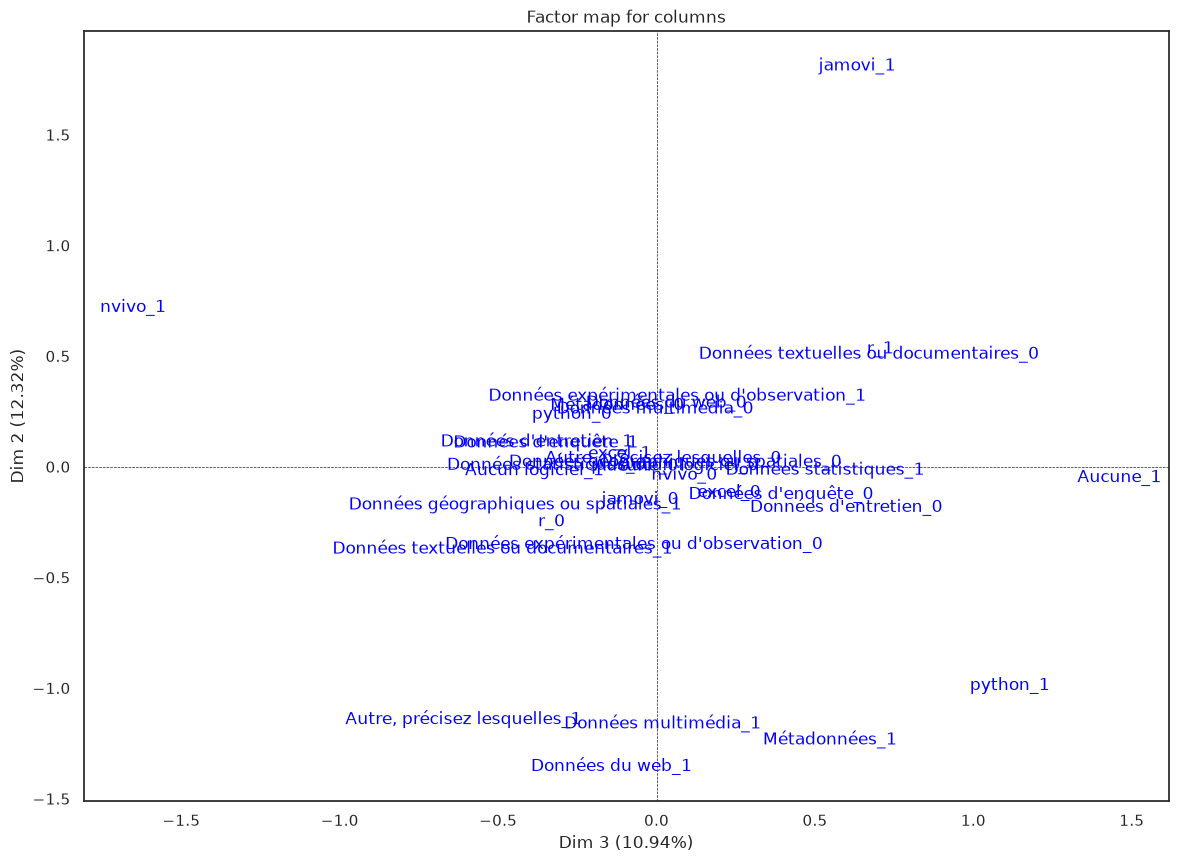

In [133]:


# Mapping simultané des points lignes et colonnes
# Les paramètres de la méthode mapping indiquent que ce sont les axes 1 et 2 qui sont ici représentés
acm.mapping_col(num_x_axis=3, num_y_axis=2, short_labels=False)



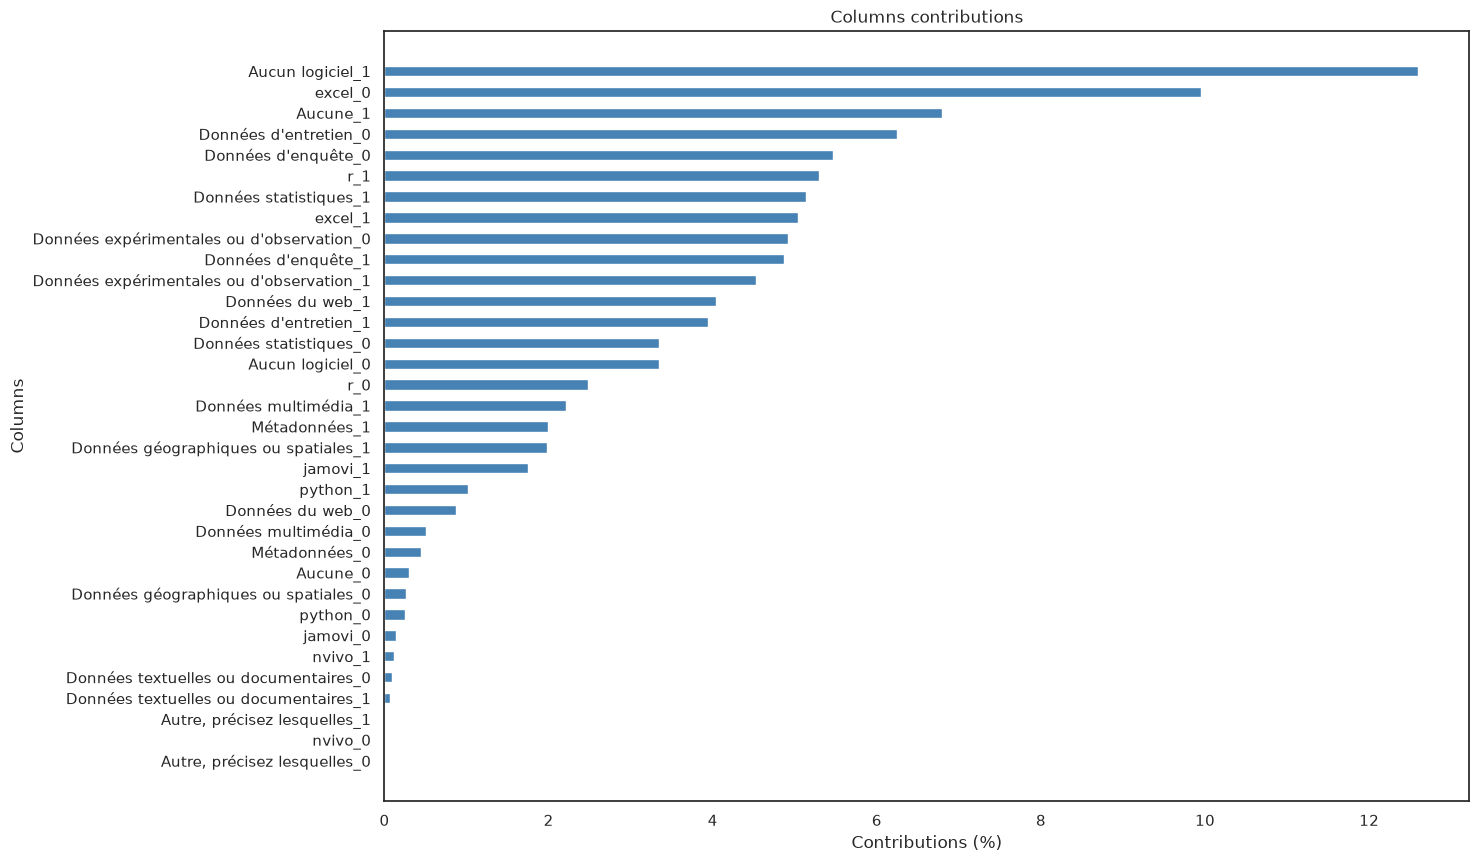

In [114]:
#ou bien graphiquement
acm.plot_col_contrib(num_axis=1, short_labels=False)

In [121]:
#affichage des COS2
print(pd.DataFrame(acm.col_cos2_[:,:2],index=df_cols.index,columns=['Cos2.F1','Cos2.F2']))

                                            Cos2.F1   Cos2.F2
Aucun logiciel_0                           0.505433  0.000085
Aucun logiciel_1                           0.505433  0.000085
Aucune_0                                   0.224769  0.000109
Aucune_1                                   0.224769  0.000109
Autre, précisez lesquelles_0               0.000375  0.045230
Autre, précisez lesquelles_1               0.000375  0.045230
Données d'enquête_0                        0.327688  0.013520
Données d'enquête_1                        0.327688  0.013520
Données d'entretien_0                      0.322994  0.020767
Données d'entretien_1                      0.322994  0.020767
Données du web_0                           0.155673  0.391759
Données du web_1                           0.155673  0.391759
Données expérimentales ou d'observation_0  0.299493  0.112028
Données expérimentales ou d'observation_1  0.299493  0.112028
Données géographiques ou spatiales_0       0.071078  0.003875
Données 

In [125]:
#affichage des COS2 cumulés
print(pd.DataFrame(np.cumsum(acm.col_cos2_[:,:2],axis=1),index=df_cols.index,columns=['Cos2.F1','Cum(Cos2).F2']))

                                            Cos2.F1  Cum(Cos2).F2
Aucun logiciel_0                           0.505433      0.505519
Aucun logiciel_1                           0.505433      0.505519
Aucune_0                                   0.224769      0.224879
Aucune_1                                   0.224769      0.224879
Autre, précisez lesquelles_0               0.000375      0.045605
Autre, précisez lesquelles_1               0.000375      0.045605
Données d'enquête_0                        0.327688      0.341208
Données d'enquête_1                        0.327688      0.341208
Données d'entretien_0                      0.322994      0.343761
Données d'entretien_1                      0.322994      0.343761
Données du web_0                           0.155673      0.547433
Données du web_1                           0.155673      0.547433
Données expérimentales ou d'observation_0  0.299493      0.411521
Données expérimentales ou d'observation_1  0.299493      0.411521
Données gé

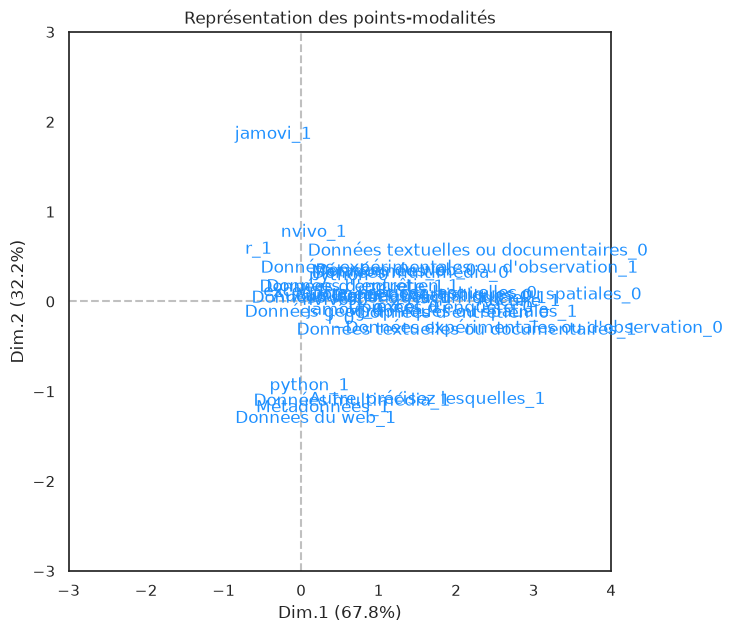

In [103]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(7,7))
ax.axis([-3,+4,-3,+3])
ax.plot([-3,+3],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[-3,+3],color='silver',linestyle='--')
ax.set_xlabel("Dim.1 (67.8%)")
ax.set_ylabel("Dim.2 (32.2%)")
plt.title("Représentation des points-modalités")
for i in range(df_cols.shape[0]):
    ax.text(acm.col_coord_[i,0],acm.col_coord_[i,1],df_cols.index[i],color='dodgerblue')
plt.show()

In [259]:
contrib12

,index,0,1
0,q1_Non,7.855986,37.624267
1,"q1_Oui, tout à fait",19.426780,0.933328
2,"q1_Oui, un peu",4.281805,12.854885
3,q2_Non,10.968982,13.351169
4,"q2_Oui, plusieurs fois",0.041049,20.926831
5,"q2_Oui, systématiquement",12.490356,2.285348
6,"q2_Oui, une fois",5.574083,4.970738
7,octavi_Ne connait pas,12.883725,2.100409
8,octavi_Non,3.416155,0.660686
9,octavi_Oui,0.156580,0.000433


In [267]:
df_os.columns[:5]

Index(['q1_so_principles', 'q2_hal_depot', 'octavi_depot_rec',
       'depot_entrepot'],
      dtype='object')

In [131]:
df_df.iloc[:,j]

0      PS8W-TJ9P
1      GNEG-5QXQ
2      FCCB-GMYA
3      CV3G-95CT
4      9EAP-NB4B
         ...    
117    32TW-JLY5
117    32TW-JLY5
117    32TW-JLY5
118    6GVE-N5NJ
118    6GVE-N5NJ
Name: q45_clé, Length: 582, dtype: object

In [132]:
#récupération des contribution sous une forme exploitable - 2 facteurs
contrib12 = pd.DataFrame(acm.col_contrib_[:,:2],index=df_cols.index)
print(contrib12)

#**calcul des carrés des rapports de corrélation par variable sur les 2 facteurs**
#structure pour les eta2
eta2 = np.zeros((17,2))
#pour chaque facteur
for h in range(2):
    #pour chaque variable
    for j in range(17):
        eta2[j,h] = (p*acm.eig_[0][h]*np.sum(contrib12.loc[np.unique(df_df.iloc[:,j])][h]))/100
#affichage
print(pd.DataFrame(eta2,index=df_df.columns[:17],columns=['F1','F2']))


                                                   0          1
Aucun logiciel_0                            3.349141   0.000856
Aucun logiciel_1                           12.592770   0.003220
Aucune_0                                    0.297877   0.000219
Aucune_1                                    6.791591   0.004998
Autre, précisez lesquelles_0                0.000398   0.072564
Autre, précisez lesquelles_1                0.011441   2.086209
Données d'enquête_0                         5.471799   0.341636
Données d'enquête_1                         4.863821   0.303677
Données d'entretien_0                       6.249526   0.608038
Données d'entretien_1                       3.938057   0.383147
Données du web_0                            0.866489   3.299716
Données du web_1                            4.043613  15.398676
Données expérimentales ou d'observation_0   4.921623   2.785839
Données expérimentales ou d'observation_1   4.524718   2.561175
Données géographiques ou spatiales_0    

KeyError: "None of [Index(['2DRU-P3AV', '2JQN-P9PA', '2QNC-8AAQ', '2Y89-7BR9', '32TW-JLY5',\n       '35EN-C9DW', '3EAA-2Q9U', '3LVR-PYLH', '3V5K-8FEA', '44RN-J48S',\n       ...\n       'X48K-M3K4', 'XA8V-2558', 'XGV3-TLNC', 'XW7R-FDND', 'Y7ZW-AP6B',\n       'YL4Q-KQAK', 'YTMC-B4DP', 'ZB5S-ABHN', 'ZBFK-V8BA', 'ZGPH-2FPH'],\n      dtype='object', length=119)] are in the [index]"

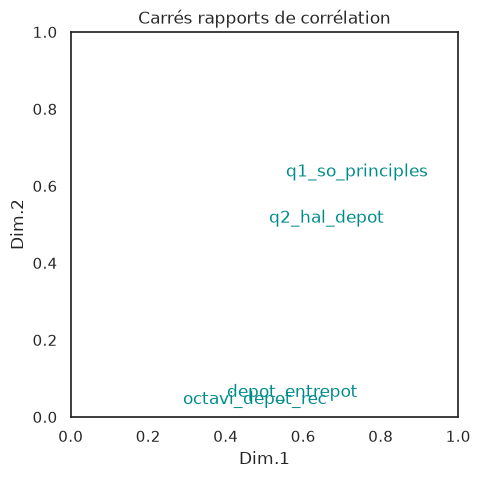

In [274]:
fix,ax = plt.subplots(figsize=(5,5))
ax.axis([0,+1,0,+1])
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Carrés rapports de corrélation")
for i in range(4):
    ax.text(eta2[i,0],eta2[i,1],df_os.columns[i],color='darkcyan')
plt.show()